# PWD Connect — Document Tampering CNN (simple version)

**Goal:** check an uploaded document image for (1) **image quality** (percentage + category) and (2) **signs of editing** (tampering score + heat-map of where).

**Pipeline:** data → exploratory data analysis (EDA) → quality score → synthetic forgeries → CNN training → evaluation on an untouched test set → testing on new documents.

**Files:** this notebook, the downloaded datasets in `data/`, and one model file `tamper_cnn.pt`. Nothing else is written.

**How to run:** *Kernel → Restart & Run All.* `QUICK = True` is a ~15-minute CPU smoke test (results are **not** meaningful). Set `QUICK = False` for the real run (a GPU is strongly recommended).

> Screening aid only. A result never proves a document is genuine or forged — a qualified person makes the decision.

## 1. Settings

In [1]:
QUICK = False                    # True = fast pipeline test; False = full training run
SEED = 42
WORK_SIDE = 1024                 # pages are resized so the longest side is this many pixels
CROP = 256 if QUICK else 384     # the CNN trains on crops so small edits stay visible
EPOCHS = 3 if QUICK else 12
STEPS = 60 if QUICK else 250     # training batches per epoch
BATCH = 8 if QUICK else 6        # 6 × 384 px fits a 2 GB GPU with mixed precision
LR = 3e-4
VAL_PAGES, TEST_PAGES = (25, 40) if QUICK else (None, None)   # None = use every page in the split
TRAIN_TYPES = ["field_edit", "copy_move", "splice"]
TEST_TYPES = TRAIN_TYPES + ["erase"]          # "erase" is never seen in training → generalisation check
QUALITY_CUTOFFS = {"POOR": 40, "GOOD": 70}

In [2]:
import io, re, zipfile, random, functools
from pathlib import Path
import numpy as np, pandas as pd, cv2, requests, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from PIL import Image, ImageDraw, ImageFont, ImageOps
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"          # mixed precision on GPU: half the memory, faster
DATA, MODEL_PATH = Path("data"), Path("tamper_cnn.pt")
DATA.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
print(f"PyTorch {torch.__version__} | device: {DEVICE} | {'QUICK test run' if QUICK else 'FULL run'}")

PyTorch 2.6.0+cu124 | device: cuda | FULL run


## 2. Data
Both datasets download automatically — no account or request needed. They contain **genuine** documents only; tampered examples are generated from them in Section 5.

| Dataset | Content | Licence | Why |
|---|---|---|---|
| **ClinOCR-Bench** | 384 synthetic clinical forms (normal, handwriting, poor, rotated, tables, mixed) | MIT | Closest to medical / disability documents |
| **FUNSD** | 199 real scanned forms | Research use | Real scanner noise and layouts |

In [3]:
SOURCES = {"ClinOCR": "https://github.com/ClinOCR-Bench/ClinOCR-Bench/releases/download/v1.0/ClinOCR-Bench-v1.0.zip",
           "FUNSD": "https://guillaumejaume.github.io/FUNSD/dataset.zip"}

def download(name):
    out = DATA / name.lower()
    if not out.exists():
        print(f"Downloading {name} …")
        r = requests.get(SOURCES[name], timeout=300); r.raise_for_status()
        zipfile.ZipFile(io.BytesIO(r.content)).extractall(out)
    return out

rows = []
for p in sorted(download("ClinOCR").rglob("*.jpg")):
    if "scans" in p.parts:
        rows.append(dict(path=str(p), dataset="ClinOCR", subset=p.parent.name,
                         group="clin_t" + re.search(r"template_(\d+)", p.stem).group(1)))   # all samples of a template stay together
for p in sorted(download("FUNSD").rglob("*.png")):
    if p.parent.name == "images" and "__MACOSX" not in p.parts:
        rows.append(dict(path=str(p), dataset="FUNSD", subset="scanned form", group="funsd_" + p.stem))
df = pd.DataFrame(rows)

# Leakage-safe split: by group (template / source document), 70 / 15 / 15
groups = df["group"].drop_duplicates().sample(frac=1, random_state=SEED).tolist()
n = len(groups)
df["split"] = df["group"].map({g: "test" if i < 0.15 * n else "val" if i < 0.30 * n else "train" for i, g in enumerate(groups)})
sets = {s: set(df.loc[df.split == s, "group"]) for s in ["train", "val", "test"]}
assert sets["train"].isdisjoint(sets["val"]) and sets["train"].isdisjoint(sets["test"]) and sets["val"].isdisjoint(sets["test"])
print(f"{len(df)} pages from {n} source groups — no group appears in two splits ✓")
pd.crosstab(df["dataset"], df["split"], margins=True)

583 pages from 215 source groups — no group appears in two splits ✓


split,test,train,val,All
dataset,,,,
ClinOCR,24,324,36,384
FUNSD,31,137,31,199
All,55,461,67,583


## 3. Image quality score (percentage + category)
A transparent, rule-based score — no training needed. Four measurements, each scaled to 0–1:

| Factor | Weight | Measures | Full marks |
|---|---|---|---|
| Sharpness | 45 % | blur (variance of the Laplacian) | crisp edges |
| Contrast | 25 % | faded scans (grey-level spread) | spread ≥ 70 |
| Brightness | 15 % | too dark / washed out | mean grey ≈ 180 |
| Resolution | 15 % | shorter side of the image | ≥ 800 px |

**Category:** POOR < 40 ≤ ACCEPTABLE < 70 ≤ GOOD.

In [4]:
def load_original(path):
    with Image.open(path) as im:
        return np.array(ImageOps.exif_transpose(im).convert("RGB"))

def quality(img):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    s = min(1.0, 1024 / max(g.shape))
    if s < 1:
        g = cv2.resize(g, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    parts = {"sharpness": np.clip((np.log10(cv2.Laplacian(g, cv2.CV_64F).var() + 1) - 1) / 2.5, 0, 1),
             "contrast": np.clip(g.std() / 70, 0, 1),
             "brightness": 1 - np.clip(abs(g.mean() - 180) / 120, 0, 1),
             "resolution": np.clip(min(img.shape[:2]) / 800, 0, 1)}
    score = 100 * (0.45 * parts["sharpness"] + 0.25 * parts["contrast"] + 0.15 * parts["brightness"] + 0.15 * parts["resolution"])
    cat = "POOR" if score < QUALITY_CUTOFFS["POOR"] else "GOOD" if score >= QUALITY_CUTOFFS["GOOD"] else "ACCEPTABLE"
    return float(score), cat, {k: float(v) for k, v in parts.items()}

q = [quality(load_original(p)) for p in df["path"]]
df["quality"], df["quality_cat"] = [x[0] for x in q], [x[1] for x in q]
df["width"], df["height"] = zip(*[Image.open(p).size for p in df["path"]])
df.groupby(["dataset", "subset"])["quality"].describe()[["count", "mean", "min", "max"]].round(1)

count  mean   min   max
dataset subset                               
ClinOCR handwriting    64.0  71.4  60.6  84.0
        mixed          64.0  60.5  34.0  91.9
        normal         64.0  75.0  66.0  83.6
        poor           64.0  59.9  31.8  91.6
        rotated        64.0  79.9  66.1  93.8
        tables         64.0  72.6  63.2  80.2
FUNSD   scanned form  199.0  83.0  68.5  98.9

## 4. Exploratory data analysis
What to check: class balance across splits, image sizes, the quality distribution, and whether the quality score separates clean from poor scans.

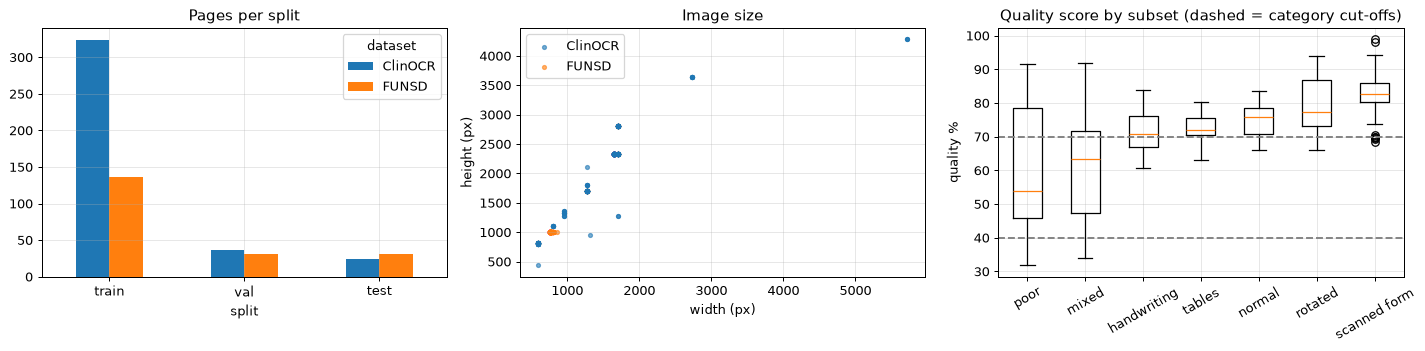

Quality categories: {'GOOD': 431, 'ACCEPTABLE': 139, 'POOR': 13}
Median quality — normal 76% vs poor 54% → the score ranks poor scans lower ✓


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
pd.crosstab(df["split"], df["dataset"]).loc[["train", "val", "test"]].plot.bar(ax=ax[0], rot=0, title="Pages per split")
for name, d in df.groupby("dataset"):
    ax[1].scatter(d["width"], d["height"], s=10, alpha=0.6, label=name)
ax[1].set(title="Image size", xlabel="width (px)", ylabel="height (px)"); ax[1].legend()
order = df.groupby("subset")["quality"].median().sort_values().index
ax[2].boxplot([df.loc[df.subset == s, "quality"] for s in order]); ax[2].set_xticks(range(1, len(order) + 1), order, rotation=30)
for v in QUALITY_CUTOFFS.values():
    ax[2].axhline(v, ls="--", c="gray")
ax[2].set(title="Quality score by subset (dashed = category cut-offs)", ylabel="quality %")
plt.tight_layout(); plt.show()

med = df.groupby("subset")["quality"].median()
print("Quality categories:", df["quality_cat"].value_counts().to_dict())
if {"poor", "normal"} <= set(med.index):
    print(f"Median quality — normal {med['normal']:.0f}% vs poor {med['poor']:.0f}% →",
          "the score ranks poor scans lower ✓" if med["poor"] < med["normal"] else "⚠ the score does NOT separate them")

### Quality score check — controlled degradation
Take good pages, make them progressively worse, and confirm the score drops each time. This is the main evidence that a rule-based score behaves sensibly.

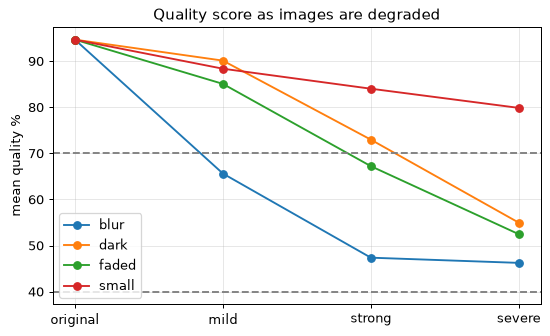

In [6]:
def degrade(img, kind, level):
    if kind == "blur":       return cv2.GaussianBlur(img, (0, 0), [0.01, 1.5, 3, 5][level])
    if kind == "dark":       return np.clip(img * [1, 0.75, 0.5, 0.3][level], 0, 255).astype(np.uint8)
    if kind == "faded":      a = [1, 0.6, 0.35, 0.2][level]; return np.clip(255 - (255 - img.astype(float)) * a, 0, 255).astype(np.uint8)
    if kind == "small":      s = [1, 0.5, 0.3, 0.15][level]; return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)

good = [load_original(p) for p in df.nlargest(10, "quality")["path"]]   # the 10 best pages
fig, ax = plt.subplots(figsize=(7, 4))
for kind in ["blur", "dark", "faded", "small"]:
    ax.plot(range(4), [np.mean([quality(degrade(im, kind, lv))[0] for im in good]) for lv in range(4)], "o-", label=kind)
for v in QUALITY_CUTOFFS.values():
    ax.axhline(v, ls="--", c="gray")
ax.set(xticks=range(4), xticklabels=["original", "mild", "strong", "severe"], ylabel="mean quality %",
       title="Quality score as images are degraded"); ax.legend(); plt.show()

## 5. Synthetic forgeries (generated in memory)
No public dataset of forged medical / disability documents is freely downloadable, so forgeries are **simulated** on the genuine pages with an exact pixel mask of what changed:

| Type | What happens | Used in |
|---|---|---|
| `field_edit` | a text field is whited-out and a new date / number is typed | train + test |
| `copy_move` | a text patch is copied to another place on the same page | train + test |
| `splice` | a text patch from a *different* document is pasted in | train + test |
| `erase` | a word is removed by in-painting | **test only** (unseen type) |

Every page — genuine or forged — is re-saved as JPEG afterwards, so the model cannot cheat by spotting "was re-compressed".

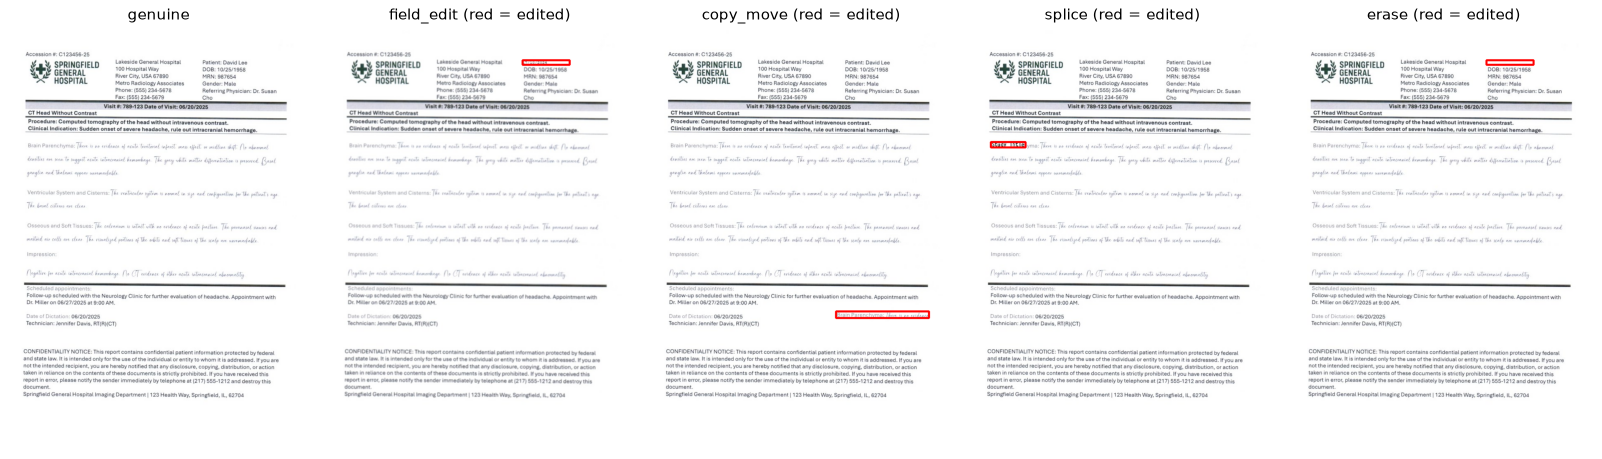

In [7]:
@functools.lru_cache(maxsize=150)
def load_page(path):
    img = load_original(path)
    s = WORK_SIDE / max(img.shape[:2])
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img

def text_boxes(img):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    bw = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]
    cnts, _ = cv2.findContours(cv2.dilate(bw, np.ones((3, 9), np.uint8)), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return [b for b in map(cv2.boundingRect, cnts) if 15 < b[2] < img.shape[1] // 3 and 7 < b[3] < 40]

def font(size, rng):
    for name in rng.permutation(["arial.ttf", "times.ttf", "cour.ttf", "DejaVuSans.ttf"]):
        try:
            return ImageFont.truetype(str(name), size)
        except OSError:
            pass
    return ImageFont.load_default()

def forge(img, kind, rng, donor=None):
    img, mask = img.copy(), np.zeros(img.shape[:2], np.uint8)
    boxes = text_boxes(img)
    if not boxes:
        return img, mask
    x, y, w, h = boxes[rng.integers(len(boxes))]
    if kind == "field_edit":
        ring = np.concatenate([img[max(0, y - 4):y, x:x + w].reshape(-1, 3), img[y + h:y + h + 4, x:x + w].reshape(-1, 3)])
        img[y:y + h, x:x + w] = np.median(ring, 0) if len(ring) else 255
        pil = Image.fromarray(img); d = ImageDraw.Draw(pil); f = font(max(8, int(h * 0.9)), rng)
        txt = rng.choice([f"{rng.integers(1, 29):02d}/{rng.integers(1, 13):02d}/20{rng.integers(10, 27)}", str(rng.integers(10, 99999)), f"{rng.integers(10, 101)}%"])
        d.text((x, y), txt, fill=(int(rng.integers(0, 60)),) * 3, font=f)
        x0, y0, x1, y1 = d.textbbox((x, y), txt, font=f)
        img = np.array(pil); mask[y:y + h, x:x + w] = 1; mask[max(0, y0):y1, max(0, x0):x1] = 1
    elif kind == "copy_move":
        sx, sy, sw, sh = boxes[rng.integers(len(boxes))]
        ty, tx = rng.integers(0, img.shape[0] - sh), rng.integers(0, img.shape[1] - sw)
        img[ty:ty + sh, tx:tx + sw] = img[sy:sy + sh, sx:sx + sw].copy(); mask[ty:ty + sh, tx:tx + sw] = 1
    elif kind == "splice" and donor is not None:
        db = text_boxes(donor)
        if db:
            sx, sy, sw, sh = db[rng.integers(len(db))]
            sh, sw = min(sh, img.shape[0] - y), min(sw, img.shape[1] - x)
            img[y:y + sh, x:x + sw] = donor[sy:sy + sh, sx:sx + sw]; mask[y:y + sh, x:x + sw] = 1
    elif kind == "erase":
        ink = np.zeros(img.shape[:2], np.uint8)
        roi = cv2.cvtColor(img[y:y + h, x:x + w], cv2.COLOR_RGB2GRAY)
        ink[y:y + h, x:x + w] = cv2.threshold(roi, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]
        img = cv2.inpaint(img, cv2.dilate(ink, np.ones((3, 3), np.uint8)), 3, cv2.INPAINT_TELEA); mask[y:y + h, x:x + w] = 1
    return img, mask

def resave(img, rng):
    if rng.random() < 0.3:
        img = cv2.GaussianBlur(img, (3, 3), 0)
    ok, buf = cv2.imencode(".jpg", img[..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, int(rng.integers(60, 96))])
    return cv2.imdecode(buf, 1)[..., ::-1].copy()

def make_example(path, kind, seed, donors):
    # kind = "genuine" or a forgery type. The same seed always gives the same example.
    rng = np.random.default_rng(seed)
    img, mask = load_page(path), None
    if kind != "genuine":
        img, mask = forge(img, kind, rng, load_page(donors[rng.integers(len(donors))]) if kind == "splice" else None)
    return resave(img, rng), mask if mask is not None else np.zeros(img.shape[:2], np.uint8)

train_paths = df.loc[df.split == "train", "path"].tolist()
fig, ax = plt.subplots(1, 5, figsize=(18, 5))
p = train_paths[3]
for a, kind in zip(ax, ["genuine"] + TEST_TYPES):
    im, m = make_example(p, kind, 7, train_paths)
    vis = im.copy(); cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(vis, cnts, -1, (255, 0, 0), 3)
    a.imshow(vis); a.set_title(kind + ("" if kind == "genuine" else " (red = edited)")); a.axis("off")
plt.tight_layout(); plt.show()

### EDA on the forgeries — how big are the edits?

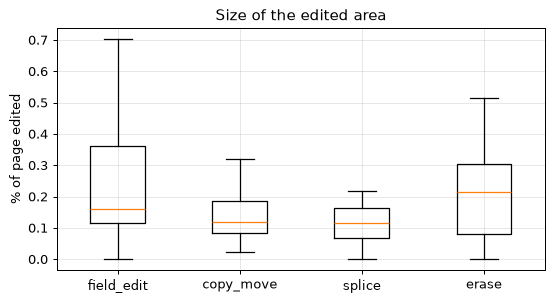

Median edit covers 0.15% of the page → shrinking the whole page to one small image would erase the evidence, so the CNN trains on 384×384 crops and checks full pages tile by tile.


In [8]:
rng = np.random.default_rng(SEED)
fr = [(k, make_example(train_paths[rng.integers(len(train_paths))], k, int(rng.integers(1e9)), train_paths)[1].mean() * 100)
      for k in TEST_TYPES for _ in range(15)]
fr = pd.DataFrame(fr, columns=["type", "edited_pct"])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot([fr.loc[fr.type == k, "edited_pct"] for k in TEST_TYPES]); ax.set_xticks(range(1, len(TEST_TYPES) + 1), TEST_TYPES)
ax.set(ylabel="% of page edited", title="Size of the edited area"); plt.show()
print(f"Median edit covers {fr.edited_pct.median():.2f}% of the page → shrinking the whole page to one small image would "
      f"erase the evidence, so the CNN trains on {CROP}×{CROP} crops and checks full pages tile by tile.")

## 6. The CNN
**U-Net with a pretrained EfficientNet-B0 encoder** (ImageNet weights). It outputs a per-pixel tampering probability map; the **page score** is the strongest (smoothed) value in the map.

Why: pretrained (works with little data), small enough for a laptop GPU, and gives a *where* map, not just yes/no.
Loss = weighted binary cross-entropy (edited pixels are rare) + Dice.

In [9]:
MEAN, STD = np.array([0.485, 0.456, 0.406], np.float32), np.array([0.229, 0.224, 0.225], np.float32)
to_tensor = lambda im: torch.from_numpy(((im.astype(np.float32) / 255 - MEAN) / STD).transpose(2, 0, 1).copy())

class Up(nn.Module):
    def __init__(self, cin, cskip, cout):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(cin + cskip, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(True),
                                  nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(True))
    def forward(self, x, skip):
        return self.conv(torch.cat([F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False), skip], 1))

class TamperUNet(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        try:
            enc = torchvision.models.efficientnet_b0(weights="IMAGENET1K_V1" if pretrained else None)
        except Exception as e:
            print(f"⚠ pretrained weights unavailable ({type(e).__name__}) — random init, results will be weak"); enc = torchvision.models.efficientnet_b0()
        self.enc = enc.features[:8]
        self.u4, self.u3, self.u2, self.u1 = Up(320, 112, 128), Up(128, 40, 64), Up(64, 24, 48), Up(48, 16, 32)
        self.head = nn.Conv2d(32, 1, 1)
    def forward(self, x):
        skips, h = {}, x
        for i, blk in enumerate(self.enc):
            h = blk(h)
            if i in (1, 2, 3, 5):
                skips[i] = h
        h = self.u1(self.u2(self.u3(self.u4(h, skips[5]), skips[3]), skips[2]), skips[1])
        return F.interpolate(self.head(h), size=x.shape[-2:], mode="bilinear", align_corners=False)

@torch.no_grad()
def predict_map(model, img, bs=16):
    # Slide a CROP×CROP window over the page and average overlapping predictions.
    model.eval(); H, W = img.shape[:2]; c, s = CROP, CROP * 3 // 4
    pad = cv2.copyMakeBorder(img, 0, max(0, c - H), 0, max(0, c - W), cv2.BORDER_CONSTANT, value=(255, 255, 255))
    Hp, Wp = pad.shape[:2]; acc, cnt = np.zeros((Hp, Wp), np.float32), np.zeros((Hp, Wp), np.float32)
    tiles = [(y, x) for y in sorted({*range(0, Hp - c + 1, s), Hp - c}) for x in sorted({*range(0, Wp - c + 1, s), Wp - c})]
    for i in range(0, len(tiles), bs):
        chunk = tiles[i:i + bs]
        with torch.autocast(DEVICE.type, enabled=AMP):
            logits = model(torch.stack([to_tensor(pad[y:y + c, x:x + c]) for y, x in chunk]).to(DEVICE))
        out = torch.sigmoid(logits.float())[:, 0].cpu().numpy()
        for (y, x), o in zip(chunk, out):
            acc[y:y + c, x:x + c] += o; cnt[y:y + c, x:x + c] += 1
    return (acc / cnt)[:H, :W]

page_score = lambda prob: float(cv2.GaussianBlur(prob, (9, 9), 0).max())

model = TamperUNet().to(DEVICE)
print(f"TamperUNet: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters")

TamperUNet: 4.5 M parameters


## 7. Training
Each batch: random training pages, half genuine and half forged (types from `TRAIN_TYPES`), cropped around the edit half of the time. Light brightness/contrast augmentation only — heavy blur or noise would destroy the traces the model needs. After each epoch the model is checked on the **validation** pages; the best epoch is kept.

In [10]:
def eval_set(split, kinds, limit):
    paths = df.loc[df.split == split, "path"].tolist()[:limit]
    # every page appears once genuine and once forged (forgery types rotate); fixed seeds → identical every time
    return [(p, "genuine", i) for i, p in enumerate(paths)] + [(p, kinds[i % len(kinds)], 10_000 + i) for i, p in enumerate(paths)]

def run_eval(model, items):
    out = []
    for p, kind, seed in items:
        img, mask = make_example(p, kind, seed, train_paths)
        prob = predict_map(model, img)
        inter, union = ((prob > 0.5) & (mask > 0)).sum(), ((prob > 0.5) | (mask > 0)).sum()
        kind = kind if mask.any() else "genuine"        # no suitable text found → the page was not actually edited
        out.append(dict(path=p, kind=kind, seed=seed, label=int(mask.any()), score=page_score(prob),
                        dice=2 * inter / max(1, (prob > 0.5).sum() + mask.sum()) if mask.any() else np.nan,
                        iou=inter / max(1, union) if mask.any() else np.nan))
    return pd.DataFrame(out)

def train_batch(rng):
    xs, ys = [], []
    for _ in range(BATCH):
        kind = "genuine" if rng.random() < 0.5 else rng.choice(TRAIN_TYPES)
        img, mask = make_example(train_paths[rng.integers(len(train_paths))], kind, int(rng.integers(1e9)), train_paths)
        img = cv2.copyMakeBorder(img, 0, max(0, CROP - img.shape[0]), 0, max(0, CROP - img.shape[1]), cv2.BORDER_CONSTANT, value=(255, 255, 255))
        mask = np.pad(mask, ((0, img.shape[0] - mask.shape[0]), (0, img.shape[1] - mask.shape[1])))
        ys_, xs_ = np.nonzero(mask)
        if len(ys_) and rng.random() < 0.5:                      # half the crops are centred on the edit
            k = rng.integers(len(ys_)); cy, cx = ys_[k], xs_[k]
        else:
            cy, cx = rng.integers(img.shape[0]), rng.integers(img.shape[1])
        y0, x0 = np.clip(cy - CROP // 2, 0, img.shape[0] - CROP), np.clip(cx - CROP // 2, 0, img.shape[1] - CROP)
        crop = np.clip(img[y0:y0 + CROP, x0:x0 + CROP] * rng.uniform(0.85, 1.15) + rng.uniform(-15, 15), 0, 255).astype(np.uint8)
        xs.append(to_tensor(crop)); ys.append(torch.from_numpy(mask[y0:y0 + CROP, x0:x0 + CROP][None].astype(np.float32)))
    return torch.stack(xs).to(DEVICE), torch.stack(ys).to(DEVICE)

def loss_fn(logits, y):
    logits = logits.float(); p = torch.sigmoid(logits)
    dice = 1 - ((2 * (p * y).sum((2, 3)) + 1) / (p.sum((2, 3)) + y.sum((2, 3)) + 1)).mean()
    return F.binary_cross_entropy_with_logits(logits, y, pos_weight=torch.tensor(5.0, device=y.device)) + dice

val_items = eval_set("val", TRAIN_TYPES, VAL_PAGES)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.amp.GradScaler(enabled=AMP)
rng, history, best = np.random.default_rng(SEED), [], -1
for epoch in range(1, EPOCHS + 1):
    model.train(); losses = []
    for step in range(STEPS):
        x, y = train_batch(rng)
        with torch.autocast(DEVICE.type, enabled=AMP):
            loss = loss_fn(model(x), y)
        opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); losses.append(loss.item())
    sched.step()
    v = run_eval(model, val_items)
    auc = roc_auc_score(v.label, v.score) if v.label.nunique() == 2 else float("nan")
    history.append(dict(epoch=epoch, train_loss=np.mean(losses), val_auc=auc, val_dice=v.dice.mean()))
    if epoch == 1 or auc > best:
        best = auc; torch.save({"state": model.state_dict(), "crop": CROP, "work_side": WORK_SIDE}, MODEL_PATH)
    print(f"epoch {epoch}/{EPOCHS}  loss {np.mean(losses):.3f}  val ROC-AUC {auc:.3f}  val Dice {v.dice.mean():.3f}" + ("  ← best, saved" if auc == best else ""))

epoch 1/12  loss 1.317  val ROC-AUC 0.525  val Dice 0.009  ← best, saved


epoch 2/12  loss 1.138  val ROC-AUC 0.560  val Dice 0.045  ← best, saved


epoch 3/12  loss 1.078  val ROC-AUC 0.535  val Dice 0.074


epoch 4/12  loss 1.038  val ROC-AUC 0.676  val Dice 0.184  ← best, saved


epoch 5/12  loss 0.991  val ROC-AUC 0.678  val Dice 0.194  ← best, saved


...

epoch 8/12  loss 0.907  val ROC-AUC 0.669  val Dice 0.262


epoch 9/12  loss 0.887  val ROC-AUC 0.696  val Dice 0.267


epoch 10/12  loss 0.879  val ROC-AUC 0.743  val Dice 0.259


epoch 11/12  loss 0.888  val ROC-AUC 0.745  val Dice 0.272


epoch 12/12  loss 0.875  val ROC-AUC 0.752  val Dice 0.281


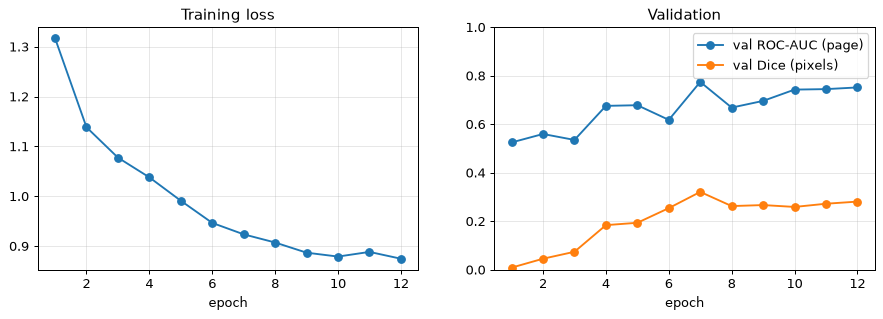

In [11]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(h.epoch, h.train_loss, "o-"); ax[0].set(title="Training loss", xlabel="epoch")
ax[1].plot(h.epoch, h.val_auc, "o-", label="val ROC-AUC (page)"); ax[1].plot(h.epoch, h.val_dice, "o-", label="val Dice (pixels)")
ax[1].set(title="Validation", xlabel="epoch", ylim=(0, 1)); ax[1].legend(); plt.show()

## 8. Evaluation on the untouched test set
The best checkpoint is reloaded. The decision **threshold is chosen on the validation set** — the point that best balances forgeries caught against false alarms (Youden's J = detection rate − false-alarm rate) — then applied once to the **test** set. The test set also contains the unseen `erase` type.

In [12]:
ckpt = torch.load(MODEL_PATH, map_location=DEVICE)
model.load_state_dict(ckpt["state"])
v = run_eval(model, val_items)
fpr_v, tpr_v, thr_v = roc_curve(v.label, v.score)
THRESHOLD = float(min(1.0, thr_v[np.argmax(tpr_v - fpr_v)]))
ckpt["threshold"] = float(THRESHOLD); torch.save(ckpt, MODEL_PATH)

t = run_eval(model, eval_set("test", TEST_TYPES, TEST_PAGES))
pred = (t.score >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(t.label, pred, labels=[0, 1]).ravel()
metrics = {"accuracy": accuracy_score(t.label, pred), "precision": precision_score(t.label, pred, zero_division=0),
           "recall (forgeries caught)": recall_score(t.label, pred, zero_division=0), "F1": f1_score(t.label, pred, zero_division=0),
           "specificity (genuine passed)": tn / max(1, tn + fp), "ROC-AUC": roc_auc_score(t.label, t.score),
           "pixel IoU": t.iou.mean(), "pixel Dice": t.dice.mean()}
print(f"Threshold (from validation): {THRESHOLD:.2f}   |   test pages: {len(t)} ({t.label.sum()} forged)")
pd.Series(metrics).round(3).to_frame("test")

Threshold (from validation): 0.99   |   test pages: 110 (46 forged)


,test
accuracy,0.691
precision,0.929
recall (forgeries caught),0.283
F1,0.433
specificity (genuine passed),0.984
ROC-AUC,0.775
pixel IoU,0.156
pixel Dice,0.224


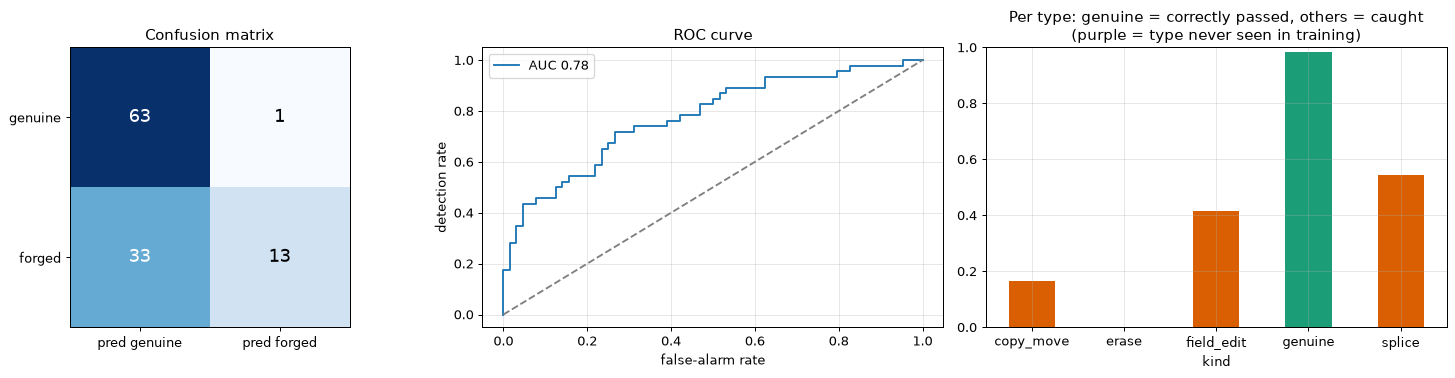

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ax[0].imshow([[tn, fp], [fn, tp]], cmap="Blues")
for (i, j), val in np.ndenumerate([[tn, fp], [fn, tp]]):
    ax[0].text(j, i, val, ha="center", va="center", fontsize=14, color="white" if val > max(tn, fp, fn, tp) / 2 else "black")
ax[0].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["pred genuine", "pred forged"], yticklabels=["genuine", "forged"], title="Confusion matrix"); ax[0].grid(False)
fpr, tpr, _ = roc_curve(t.label, t.score)
ax[1].plot(fpr, tpr, label=f"AUC {metrics['ROC-AUC']:.2f}"); ax[1].plot([0, 1], [0, 1], "--", c="gray")
ax[1].set(title="ROC curve", xlabel="false-alarm rate", ylabel="detection rate"); ax[1].legend()
per = t.assign(pred=pred).groupby("kind")["pred"].mean()
per["genuine"] = 1 - per["genuine"]
per.plot.bar(ax=ax[2], rot=0, color=["#1b9e77" if k == "genuine" else "#d95f02" if k in TRAIN_TYPES else "#7570b3" for k in per.index])
ax[2].set(title="Per type: genuine = correctly passed, others = caught\n(purple = type never seen in training)", ylim=(0, 1))
plt.tight_layout(); plt.show()

## 9. Testing — how does it behave?
**(a) Examples** of correct catches, misses and false alarms. **(b) Robustness:** the same test pages after extra compression, blur and lower resolution.

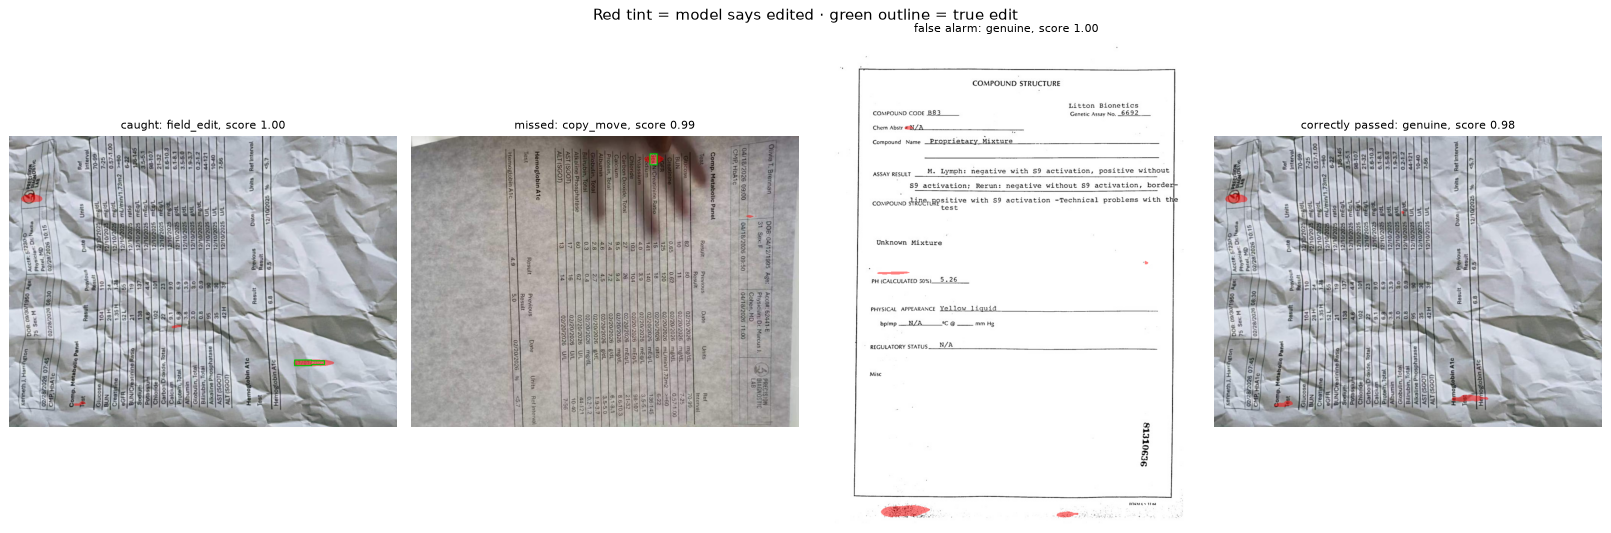

In [14]:
def show(ax, img, prob, mask=None, title=""):
    vis = np.where((prob > 0.5)[..., None], (0.5 * img + 0.5 * np.array([255, 0, 0])).astype(np.uint8), img)
    if mask is not None and mask.any():
        cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE); cv2.drawContours(vis, cnts, -1, (0, 200, 0), 2)
    ax.imshow(vis); ax.set_title(title, fontsize=9); ax.axis("off")

t["pred"] = pred
cases = {"caught": t[(t.label == 1) & (t.pred == 1)], "missed": t[(t.label == 1) & (t.pred == 0)],
         "false alarm": t[(t.label == 0) & (t.pred == 1)], "correctly passed": t[(t.label == 0) & (t.pred == 0)]}
fig, ax = plt.subplots(1, 4, figsize=(18, 6))
for a, (name, d) in zip(ax, cases.items()):
    if len(d):
        r = d.iloc[0]; img, mask = make_example(r.path, r.kind, r.seed, train_paths)
        show(a, img, predict_map(model, img), mask, f"{name}: {r.kind}, score {r.score:.2f}")
    else:
        a.set_title(f"{name}: none"); a.axis("off")
plt.suptitle("Red tint = model says edited · green outline = true edit"); plt.tight_layout(); plt.show()

In [15]:
conditions = {"as tested": lambda im: im,
              "heavy JPEG (q=40)": lambda im: cv2.imdecode(cv2.imencode(".jpg", im[..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, 40])[1], 1)[..., ::-1].copy(),
              "blur": lambda im: cv2.GaussianBlur(im, (0, 0), 1.2),
              "half resolution": lambda im: cv2.resize(cv2.resize(im, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA), (im.shape[1], im.shape[0]))}
items = eval_set("test", TEST_TYPES, 20)
rob = {}
for name, fn in conditions.items():
    lab, sc = [], []
    for p, kind, seed in items:
        img, mask = make_example(p, kind, seed, train_paths)
        lab.append(int(mask.any())); sc.append(page_score(predict_map(model, fn(img))))
    rob[name] = roc_auc_score(lab, sc)
pd.Series(rob).round(3).to_frame("test ROC-AUC")

,test ROC-AUC
as tested,0.868
heavy JPEG (q=40),0.813
blur,0.843
half resolution,0.920


### Try it on your own document
`analyze("path/to/file.jpg")` — JPG, PNG or PDF (first page). Prints quality % + category and the tampering result, and shows the heat-map.

Image quality : 77% — GOOD   (sharpness 77% · contrast 55% · brightness 91% · resolution 96%)
Tampering     : score 1.00 (threshold 0.99) → POSSIBLE ALTERATION — refer for human verification


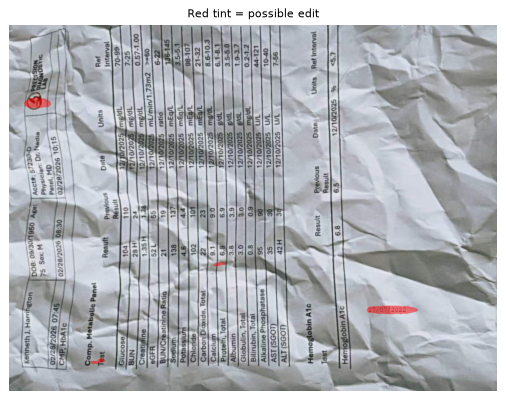

In [16]:
ckpt = torch.load(MODEL_PATH, map_location=DEVICE)
model.load_state_dict(ckpt["state"]); THRESHOLD = ckpt["threshold"]

def analyze(src):
    if str(src).lower().endswith(".pdf"):
        import pymupdf
        pix = pymupdf.open(src)[0].get_pixmap(dpi=150, alpha=False)
        orig = np.frombuffer(pix.samples, np.uint8).reshape(pix.height, pix.width, pix.n)[..., :3].copy()
    else:
        orig = load_original(src) if isinstance(src, (str, Path)) else src
    score_q, cat, parts = quality(orig)
    s = WORK_SIDE / max(orig.shape[:2]); img = cv2.resize(orig, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else orig
    prob = predict_map(model, img); score = page_score(prob)
    print(f"Image quality : {score_q:.0f}% — {cat}   (" + " · ".join(f"{k} {v * 100:.0f}%" for k, v in parts.items()) + ")")
    print(f"Tampering     : score {score:.2f} (threshold {THRESHOLD:.2f}) → "
          + ("POSSIBLE ALTERATION — refer for human verification" if score >= THRESHOLD else "no significant alteration detected by the model"))
    if cat == "POOR":
        print("⚠ Poor image quality — request a clearer scan; the tampering result is unreliable.")
    fig, ax = plt.subplots(figsize=(7, 9)); show(ax, img, prob, title="Red tint = possible edit"); plt.show()

r = t[t.label == 1].iloc[0]
demo, _ = make_example(r.path, r.kind, r.seed, train_paths)
analyze(demo)          # a forged test page; replace with analyze(r"C:\path\to\your\document.jpg")

## 10. Summary and limitations

In [17]:
print("QUICK TEST RUN — numbers are not meaningful\n" if QUICK else "", end="")
print(f"Data: {len(df)} genuine pages ({', '.join(f'{k} {v}' for k, v in df.dataset.value_counts().items())}); "
      f"split by source group {dict(df.split.value_counts())}")
print(f"Quality score: categories {df.quality_cat.value_counts().to_dict()}")
print(f"Model: EfficientNet-B0 U-Net, {EPOCHS} epochs × {STEPS} batches, best val ROC-AUC {max(h.val_auc):.3f}, threshold {THRESHOLD:.2f}")
print("Test: " + " | ".join(f"{k} {v:.3f}" for k, v in metrics.items()))
print(f"Unseen 'erase' edits caught: {t[t.kind == 'erase'].pred.mean():.0%}   |   robustness ROC-AUC: " + ", ".join(f"{k} {v:.2f}" for k, v in rob.items()))
print(f"Saved: {MODEL_PATH.resolve()}")

Data: 583 genuine pages (ClinOCR 384, FUNSD 199); split by source group {'train': np.int64(461), 'val': np.int64(67), 'test': np.int64(55)}
Quality score: categories {'GOOD': 431, 'ACCEPTABLE': 139, 'POOR': 13}
Model: EfficientNet-B0 U-Net, 12 epochs × 250 batches, best val ROC-AUC 0.774, threshold 0.99
Test: accuracy 0.691 | precision 0.929 | recall (forgeries caught) 0.283 | F1 0.433 | specificity (genuine passed) 0.984 | ROC-AUC 0.775 | pixel IoU 0.156 | pixel Dice 0.224
Unseen 'erase' edits caught: 0%   |   robustness ROC-AUC: as tested 0.87, heavy JPEG (q=40) 0.81, blur 0.84, half resolution 0.92
Saved: C:\Users\sam\Desktop\pwd_access_notebook\simple_cnn\tamper_cnn.pt


**Limitations.** The forgeries are simulated, so test scores measure how well the model finds *these* edits — real forgers behave differently (the unseen `erase` result hints at how well it generalises). Neither dataset contains Kenyan medical or disability documents. The quality score is rule-based, not learned from human ratings. Before any real use: test on real, consented, anonymised documents (Data Protection Act, 2019), including a few known-altered ones, and keep a human reviewer in charge of every decision.